# Étape 1.1 — Analyse de la qualité des données

> **Énoncé (1.1)** : évaluer la qualité des données et identifier les variables non pertinentes (identifiants, variables redondantes ou de variabilité insuffisante) ; analyser les valeurs manquantes et proposer une stratégie (suppression, imputation, modalité spécifique) ; vérifier la cohérence (doublons, valeurs incohérentes, plages de valeurs, variables constantes) et justifier les décisions.

Ce notebook reprend le script `etape_1_1_qualite.py` : mêmes calculs, mêmes résultats, enregistrés dans `resultats/`. Les décisions et l'interprétation des résultats sont détaillées dans [README.md](README.md) (version LaTeX : `README.tex`).

**Contenu de l'étape :**


A. Identifiants et variables techniques.
B. Mise au format : réponses multiples, recodage des modalités, conversion du texte
   libre en nombres, construction du coût total du sinistre.
C. Cohérence : doublons, valeurs hors plage, contradictions entre questions.
D. Valeurs manquantes : analyse et stratégie (suppression, imputation, modalité spécifique).
E. Variables constantes ou redondantes, décisions de conservation / exclusion.
F. Export du jeu de données nettoyé.


## Préparation

Bibliothèques, module commun du projet, dossier de résultats et journal.

In [1]:
import sys
from pathlib import Path

# Le notebook s'exécute dans le dossier de l'étape : on remonte jusqu'à la racine du projet
RACINE_PROJET = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "commun" / "outils.py").exists())
sys.path.insert(0, str(RACINE_PROJET))

import numpy as np
import pandas as pd

from commun import outils as o

RES = o.dossier_resultats("1.1")
log = o.Journal(RES, "Étape 1.1 — Qualité des données")
plt = o.style_graphique()
C = o.COULEURS

brut, libelles = o.charger_donnees_brutes()
df = brut.copy()
n0 = len(df)

# Étape 1.1 — Qualité des données


## A. Identifiants et variables techniques

In [2]:
log.section("A. Identifiants et variables techniques")
ids = df["id"]
sequentiel = ids.is_unique and ids.min() == 1 and ids.max() == n0 and len(ids) == n0
log(f"id : {ids.nunique()} valeurs distinctes pour {n0} lignes, de {ids.min()} à {ids.max()}"
    f" — séquentiel sans trou : {'oui' if sequentiel else 'non'}")
log("-> numéro d'ordre de saisie, sans contenu informatif : conservé comme clé, exclu des modèles.");


## A. Identifiants et variables techniques

id : 4076 valeurs distinctes pour 4076 lignes, de 1 à 4076 — séquentiel sans trou : oui
-> numéro d'ordre de saisie, sans contenu informatif : conservé comme clé, exclu des modèles.


## B. Mise au format

In [3]:
log.section("B1. Réponses multiples")
# Règles de recodage : (motif recherché dans la réponse en minuscules, modalité finale)
OUI_NON_MG = [(r"\beny\b", "Oui"), (r"\btsia\b", "Non")]
OUI_NON_FR = [(r"\boui\b", "Oui"), (r"\bnon\b", "Non")]
REGLES = {
    "sexe": [(r"féminin", "Femme"), (r"masculin", "Homme")],
    "lien_chef_menage": [(r"chef de ménage", "Chef de ménage"), (r"epouse", "Conjoint(e)"),
                         (r"enfant", "Enfant"), (r"parent", "Parent"), (r"frère|sœur", "Frère/sœur")],
    "statut_pro": [(r"les deux", "Salarié et indépendant"), (r"indépendant", "Indépendant"),
                   (r"salarié", "Salarié")],
    "statut_matrimonial": [(r"marié", "Marié(e)"), (r"c[ée]libataire", "Célibataire"),
                           (r"veuf", "Veuf(ve)"), (r"divorcé", "Divorcé(e)")],
    "secteur": [(r"agricole", "Agriculture"), (r"elevage", "Élevage, pêche"),
                (r"artisan", "Artisanat"), (r"agroalimentaire", "Agroalimentaire"),
                (r"commerce", "Commerce"), (r"entretien", "Entretien, réparation"),
                (r"matériaux", "Matériaux de construction"), (r"hôtel", "Hôtellerie, restauration"),
                (r"transport", "Transport"), (r"education", "Éducation"), (r"santé", "Santé"),
                (r"textile", "Textile"), (r"bancaire", "Banque, finance"), (r"energie", "Énergie"),
                (r"communication", "Communication, médias"), (r"distribution", "Distribution"),
                (r"mécanique", "Construction mécanique"), (r"loisirs", "Loisirs, tourisme"),
                (r"services", "Services"), (r"bâtiment", "Bâtiment"),
                (r"electronique", "Électronique"), (r"informatique", "Informatique"),
                (r"métallurgique", "Métallurgie"), (r"chimique", "Industrie chimique"),
                (r"autre", "Autre")],
    "activite_conjoint": [(r"indépendant", "Indépendant"), (r"salarié", "Salarié"),
                          (r"retraité", "Retraité"), (r"sans activité", "Sans activité"),
                          (r"meme travail", "Même activité"), (r"autre", "Autre")],
    "niveau_etude": [(r"université", "Université"), (r"lycée", "Lycée"), (r"collège", "Collège"),
                     (r"primaire", "Primaire"), (r"analphabète", "Analphabète")],
    "statut_residence": [(r"tompon", "Propriétaire"), (r"manofa", "Locataire")],
    "source_eau": [(r"branchement", "Branchement à domicile"), (r"borne", "Borne fontaine"),
                   (r"puits", "Puits"), (r"autre", "Autre")],
    "source_electricite": [(r"jirama", "Réseau JIRAMA"), (r"solaire", "Solaire"),
                           (r"petrole", "Pétrole"), (r"bougie", "Bougie"), (r"autre", "Autre")],
    "energie_cuisine": [(r"charbon", "Charbon"), (r"hazo", "Bois"), (r"gaz", "Gaz"),
                        (r"electricit", "Électricité")],
    "type_toilette": [(r"chasse", "Chasse d'eau"), (r"fosse", "Latrines"),
                      (r"sèches", "Toilettes sèches"), (r"ankalamanjana", "Plein air"),
                      (r"autre", "Autre")],
    "transport_travail": [(r"tongotra", "À pied"), (r"pas de déplacement", "Travail à domicile"),
                          (r"moto", "Moto"), (r"transport en commun", "Transport en commun"),
                          (r"bicyclette", "Vélo"), (r"voiture", "Voiture"),
                          (r"taxi", "Taxi, taxi-moto"), (r"autre", "Autre")],
    "revenu": [(r"^moins de 100", "<100k"), (r"^100 ?000 ?ar- ?200", "100-200k"),
               (r"^200 ?000 ?ar-300", "200-300k"), (r"^300 ?000 ?ar-400", "300-400k"),
               (r"^400 ?000 ?ar ?- ?500", "400-500k"), (r"^500 ?000 ?ar- ?1 ?000 ?000", "500k-1M"),
               (r"^plus de 1 ?000 ?000", ">1M")],
    "epargne": OUI_NON_MG, "dettes": OUI_NON_MG, "lunettes": OUI_NON_MG,
    "effort_physique": [(r"toujours", "Toujours"), (r"souvent", "Souvent"), (r"parfois", "Parfois"),
                        (r"rarement", "Rarement"), (r"jamais", "Jamais")],
    "duree_effort": [(r"moins de 1", "<1 h"), (r"1 à 3", "1-3 h"), (r"3 à 5", "3-5 h"),
                     (r"plus de 5", ">5 h")],
    "pb_sante_travail": [(r"régulièrement", "Régulièrement"), (r"oui, parfois", "Parfois"),
                         (r"rarement", "Rarement"), (r"jamais", "Jamais")],
    "arret_maladie": [(r"plusieurs", "Plusieurs fois"), (r"une ou deux", "Une ou deux fois"),
                      (r"jamais", "Jamais")],
    "impact_travail_sante": [(r"importante", "Important"), (r"modérée", "Modéré"),
                             (r"pas vraiment", "Faible"), (r"pas du tout", "Aucun")],
    "repos_recent": [(r"plusieurs", "Plusieurs fois"), (r"une fois", "Une fois"),
                     (r"jamais", "Jamais")],
    "couverture": OUI_NON_FR, "ancienne_couverture": OUI_NON_FR,
    "interet_couverture": [(r"tout à fait", "Tout à fait"), (r"plutôt oui", "Plutôt oui"),
                           (r"plutôt non", "Plutôt non"), (r"pas du tout", "Pas du tout")],
    "maladie_chronique": OUI_NON_FR, "renoncement_soins": OUI_NON_FR,
    "dentiste": [(r"matetika", "Souvent"), (r"indraindray", "Parfois"), (r"tsia", "Jamais")],
    "douleur": [(r"très", "Très douloureux"), (r"peu", "Peu douloureux"),
                (r"pas douloureux", "Pas douloureux"), (r"douloureux", "Douloureux")],
    "type_recours": [(r"automédication", "Automédication"), (r"tradipraticien", "Tradipraticien"),
                     (r"médecin libre", "Médecin libre"), (r"csb", "CSB public"),
                     (r"dispensaire", "Dispensaire privé"), (r"hôpital public", "Hôpital public"),
                     (r"hôpital privé", "Hôpital privé"),
                     (r"ostie|esia|service medical|m[ée]dico", "Service médical d'entreprise"),
                     (r"à distance", "Consultation à distance"),
                     (r"domicile", "Consultation à domicile"), (r"ne rien faire", "Aucun recours"),
                     (r"autre", "Autre")],
    "satisfaction": [(r"tout à fait", "Tout à fait satisfait"), (r"plutôt satisfait", "Plutôt satisfait"),
                     (r"plutôt pas", "Plutôt pas satisfait"), (r"pas du tout", "Pas du tout satisfait")],
    "impact_autre": [(r"organisation", "Organisation du travail"), (r"perte de client", "Perte de clients"),
                     (r"perte d'emploi", "Perte d'emploi"), (r"autre", "Autre")],
    "impact_maladie_activite": [(r"très affecté", "Très affecté"), (r"pas du tout", "Pas affecté"),
                                (r"affecté", "Affecté")],
    "recuperation_activite": [(r"plus dur", "Travail plus dur"), (r"rattrapage", "Rattrapage après guérison"),
                              (r"pas de récupération", "Pas de récupération"),
                              (r"effectué par les autres", "Travail fait par d'autres"),
                              (r"autres", "Autre")],
}

lignes_multi, lignes_recodage = [], []
for var, regles in REGLES.items():
    resolu, multiples = o.premiere_modalite(df[var])
    recode, non_reconnues = o.recoder(resolu, regles)
    if non_reconnues:
        raise ValueError(f"{var} : modalités non reconnues {non_reconnues}")
    lignes_multi.append({"variable": var, "cellules_multiples": int(multiples.sum()),
                         "pct_cellules": 100 * multiples.mean()})
    correspondance = (pd.DataFrame({"reponse_brute": resolu, "modalite": recode})
                      .dropna().groupby(["reponse_brute", "modalite"]).size()
                      .rename("effectif").reset_index())
    correspondance.insert(0, "variable", var)
    lignes_recodage.append(correspondance)
    df[var] = recode

multi = pd.DataFrame(lignes_multi).sort_values("cellules_multiples", ascending=False)
o.sauver_table(multi, RES, "reponses_multiples")
o.sauver_table(pd.concat(lignes_recodage), RES, "recodage_modalites")
log("Règle : on garde la première modalité citée (supposée être la réponse principale).")
log(f"Cellules résolues : {int(multi.cellules_multiples.sum())} sur "
    f"{len(REGLES)} variables recodées.")
log.table(multi[multi.cellules_multiples > 0], index=False, floatfmt=".2f")

log.section("B2. Conversion du texte libre en nombres")
CONVERSIONS = {
    "anciennete_emploi": o.texte_vers_annees, "distance_travail": o.texte_vers_km,
    "heures_jour": o.texte_vers_heures, "jours_semaine": o.texte_vers_jours_semaine,
    "nb_employes": o.texte_vers_effectif, "jours_arret": o.texte_vers_jours,
    "distance_soins": o.texte_vers_km,
    **{c: o.texte_vers_montant for c in o.COUTS},
}
statuts = []
for var, fonction in CONVERSIONS.items():
    valeurs, statut = o.convertir(df[var], fonction)
    df[var] = valeurs
    comptes = statut.value_counts()
    statuts.append({"variable": var, **comptes.to_dict()})
statuts = pd.DataFrame(statuts).fillna(0).set_index("variable").astype(int)
ordre_statuts = ["numerique", "zero_code", "zero_texte", "texte_nombre", "fourchette", "calcul",
                 "correction_manuelle", "inconnu", "manquant"]
statuts = statuts[[s for s in ordre_statuts if s in statuts.columns]]
o.sauver_table(statuts, RES, "conversion_texte_nombre", index=True)
log("numerique = nombre pur ; zero_code = 'O', '00', 'P' ; zero_texte = phrase signifiant 'rien' ;")
log("texte_nombre = nombre extrait d'une phrase ; inconnu = texte sans valeur exploitable (-> manquant)")
log.table(statuts)

log.section("B3. Coût total du dernier épisode (variable de sévérité)")
renseignes = df[o.COUTS].notna().sum(axis=1)
df["nb_couts_renseignes"] = renseignes
df["cout_total"] = df[o.COUTS].sum(axis=1, min_count=1)
log(f"Au moins un coût renseigné : {int((renseignes > 0).sum())} individus ; "
    f"les 6 renseignés : {int((renseignes == 6).sum())} ; aucun : {int((renseignes == 0).sum())}")
log("Règle : un poste vide à côté de postes renseignés est compté 0 (pas de dépense déclarée) ;")
log("        si les six postes sont vides, cout_total est manquant.")
recap_couts = pd.DataFrame({
    "renseignes": df[o.COUTS + ["cout_total"]].notna().sum(),
    "pct_positifs": 100 * (df[o.COUTS + ["cout_total"]] > 0).sum() / df[o.COUTS + ["cout_total"]].notna().sum(),
    "mediane_si_positif": df[o.COUTS + ["cout_total"]].where(df[o.COUTS + ["cout_total"]] > 0).median(),
    "moyenne_si_positif": df[o.COUTS + ["cout_total"]].where(df[o.COUTS + ["cout_total"]] > 0).mean(),
    "max": df[o.COUTS + ["cout_total"]].max(),
})
o.sauver_table(recap_couts, RES, "couts_par_poste", index=True)
log.table(recap_couts, floatfmt=",.0f");


## B1. Réponses multiples



Règle : on garde la première modalité citée (supposée être la réponse principale).
Cellules résolues : 1305 sur 35 variables recodées.


variable,cellules_multiples,pct_cellules
secteur,355,8.71
type_recours,222,5.45
source_electricite,193,4.74
energie_cuisine,190,4.66
revenu,97,2.38
transport_travail,88,2.16
activite_conjoint,37,0.91
recuperation_activite,32,0.79
source_eau,22,0.54
impact_autre,18,0.44



## B2. Conversion du texte libre en nombres



numerique = nombre pur ; zero_code = 'O', '00', 'P' ; zero_texte = phrase signifiant 'rien' ;
texte_nombre = nombre extrait d'une phrase ; inconnu = texte sans valeur exploitable (-> manquant)


,numerique,zero_code,zero_texte,texte_nombre,fourchette,calcul,correction_manuelle,inconnu,manquant
variable,,,,,,,,,
anciennete_emploi,2986,1,0,968,7,14,0,85,15
distance_travail,1667,672,77,1199,181,0,0,250,30
heures_jour,3305,0,4,586,64,0,0,106,11
jours_semaine,3287,2,4,709,12,0,0,50,12
nb_employes,2716,590,57,24,6,0,0,8,675
jours_arret,2368,528,172,814,8,5,0,12,169
distance_soins,1460,1479,16,896,19,0,0,14,192
cout_consultation,945,2826,6,30,1,2,0,8,258
cout_hospitalisation,195,3569,7,6,0,0,0,1,298



## B3. Coût total du dernier épisode (variable de sévérité)

Au moins un coût renseigné : 3869 individus ; les 6 renseignés : 3602 ; aucun : 207
Règle : un poste vide à côté de postes renseignés est compté 0 (pas de dépense déclarée) ;
        si les six postes sont vides, cout_total est manquant.


,renseignes,pct_positifs,mediane_si_positif,moyenne_si_positif,max
cout_consultation,3810,26,"10,000","14,610","500,000"
cout_hospitalisation,3777,5,"10,000","67,289","7,000,000"
cout_medicaments,3830,76,"10,000","26,450","1,600,000"
cout_deplacement,3804,14,"4,000","11,009","450,000"
cout_alimentation,3704,12,"5,000","14,185","300,000"
cout_autres,3757,5,"5,000","45,258","2,400,000"
cout_total,3869,79,"13,004","41,191","9,500,000"


In [4]:
# Fokotany : harmonisation de l'écriture (variable descriptive)
VARIANTES = {"andrefatsena": "andrefantsena", "ampivarotanomby": "ampivarotan'omby",
             "ampivarontanomby": "ampivarotan'omby", "ampivatotan'omby": "ampivarotan'omby",
             "andriambelinomby": "andriambelonomby"}
fk = df["fokotany"].map(o.normaliser).map(lambda s: VARIANTES.get(s, s) if s else s)
log(f"Fokotany : {brut['fokotany'].nunique()} écritures brutes -> {fk.nunique()} après harmonisation")
df["fokotany"] = fk.map(lambda s: s.title() if isinstance(s, str) else s)

NON_MALADE = {"tsy narary", "ts narary", "tsy misy", "tsisy", "tsy nisy", "0", "o", "00"}
df["declare_non_malade"] = df["type_maladie"].map(o.normaliser).isin(NON_MALADE).astype(int)
log(f"Individus déclarant ne pas avoir été malades (type_maladie) : {df['declare_non_malade'].sum()}");

Fokotany : 237 écritures brutes -> 159 après harmonisation
Individus déclarant ne pas avoir été malades (type_maladie) : 262


## C. Cohérence

In [5]:
log.section("C1. Doublons")
cles = [c for c in o.CODES if c != "id"]
doublons = df[brut.drop(columns="id").duplicated(keep=False)].sort_values(cles[:5])
log(f"Lignes strictement identiques (hors id) : {len(doublons)} lignes, ids {doublons['id'].tolist()}")
a_supprimer = df.loc[brut.drop(columns="id").duplicated(keep="first"), "id"].tolist()
df = df[~df["id"].isin(a_supprimer)].reset_index(drop=True)
log(f"-> suppression de la seconde occurrence : ids {a_supprimer} ; reste {len(df)} individus")

log.section("C2. Valeurs hors plage (impossibles) -> mises à manquant")
avant = df.copy()
regles_plage = [
    ("age", (df.age < 15) | (df.age > 100), "Âge hors de 15–100 ans (enquête auprès d'actifs)"),
    ("taille_menage", df.taille_menage < 1, "Ménage de moins d'une personne"),
    ("nb_actifs_menage", df.nb_actifs_menage > df.taille_menage, "Plus d'actifs que de membres du ménage"),
    ("budget_alim", df.budget_alim > 100, "Part de budget > 100 % (montant saisi au lieu d'un %)"),
    ("budget_sante", df.budget_sante > 100, "Part de budget > 100 % (montant saisi au lieu d'un %)"),
    ("budget_elec", df.budget_elec > 100, "Part de budget > 100 % (montant saisi au lieu d'un %)"),
    ("prime_souhaitee", df.prime_souhaitee < 0, "Prime négative"),
    ("prime_souhaitee", (df.prime_souhaitee > 0) & (df.prime_souhaitee < 100),
     "Prime entre 1 et 99 Ar (unité ambiguë : milliers d'Ariary ?)"),
    ("nb_maladies_graves", df.nb_maladies_graves < 0, "Nombre de maladies négatif"),
    ("heures_jour", (df.heures_jour > 24) | (df.heures_jour == 0), "Heures par jour > 24 ou nulles"),
    ("jours_semaine", (df.jours_semaine > 7) | (df.jours_semaine == 0), "Jours par semaine > 7 ou nuls"),
    ("anciennete_emploi", df.anciennete_emploi > df.age - 5, "Ancienneté supérieure à (âge − 5) ans"),
    ("jours_arret", df.jours_arret > 365, "Arrêt de travail de plus d'un an pour un épisode"),
]
lignes = []
for var, masque, motif in regles_plage:
    masque = masque.fillna(False)
    exemples = ", ".join(f"{v:g}" for v in sorted(df.loc[masque, var].unique())[:8])
    lignes.append({"variable": var, "regle": motif, "valeurs_concernees": int(masque.sum()),
                   "exemples": exemples})
    df.loc[masque, var] = np.nan
plages = pd.DataFrame(lignes)
o.sauver_table(plages, RES, "controles_plages")
log.table(plages, index=False)

log.section("C3. Contradictions entre questions (signalées, non corrigées)")
budgets = df[["budget_alim", "budget_sante", "budget_elec"]]
contradictions = pd.DataFrame([
    ("Déclare ne pas avoir été malade mais nb_maladies_graves > 0",
     int(((df.declare_non_malade == 1) & (df.nb_maladies_graves > 0)).sum()),
     "Conservé : nb_maladies_graves est la variable cible ; type_maladie peut décrire une "
     "période différente."),
    ("Déclare ne pas avoir été malade mais cout_total > 0",
     int(((df.declare_non_malade == 1) & (df.cout_total > 0)).sum()),
     "Conservé (dépenses de santé possibles sans « maladie » ressentie)."),
    ("Somme des trois parts de budget > 100 % (chaque part ≤ 100 %)",
     int((budgets.sum(axis=1, min_count=3) > 100).sum()),
     "Conservé : réponses approximatives, chaque part reste plausible."),
    ("Conjoint(e) du chef de ménage mais statut non marié",
     int(((df.lien_chef_menage == "Conjoint(e)") & (df.statut_matrimonial != "Marié(e)")
          & df.statut_matrimonial.notna()).sum()),
     "Conservé (union libre possible)."),
    ("Célibataire avec une activité de conjoint renseignée",
     int(((df.statut_matrimonial == "Célibataire") & df.activite_conjoint.notna()).sum()),
     "Conservé ; activite_conjoint n'est pas utilisée dans les modèles."),
], columns=["controle", "individus", "decision"])
o.sauver_table(contradictions, RES, "contradictions")
log.table(contradictions, index=False);


## C1. Doublons

Lignes strictement identiques (hors id) : 3 lignes, ids [3460, 3624, 3898]
-> suppression de la seconde occurrence : ids [3624, 3898] ; reste 4074 individus

## C2. Valeurs hors plage (impossibles) -> mises à manquant



variable,regle,valeurs_concernees,exemples
age,Âge hors de 15–100 ans (enquête auprès d'actifs),4,"3, 5, 107, 112"
taille_menage,Ménage de moins d'une personne,5,"-6, 0"
nb_actifs_menage,Plus d'actifs que de membres du ménage,12,"2, 4, 5, 6, 7"
budget_alim,Part de budget > 100 % (montant saisi au lieu d'un %),12,"600, 2000, 5000, 40000, 50000, 60000, 70000, 100000"
budget_sante,Part de budget > 100 % (montant saisi au lieu d'un %),11,"5000, 10000, 20000, 50000, 70000"
budget_elec,Part de budget > 100 % (montant saisi au lieu d'un %),9,"3000, 5000, 10000, 15000, 17000"
prime_souhaitee,Prime négative,3,-5000
prime_souhaitee,Prime entre 1 et 99 Ar (unité ambiguë : milliers d'Ariary ?),18,"1, 4, 5, 8, 10, 20, 30, 40"
nb_maladies_graves,Nombre de maladies négatif,1,-1
heures_jour,Heures par jour > 24 ou nulles,9,"0, 406"



## C3. Contradictions entre questions (signalées, non corrigées)



controle,individus,decision
Déclare ne pas avoir été malade mais nb_maladies_graves > 0,13,Conservé : nb_maladies_graves est la variable cible ; type_maladie peut décrire une période différente.
Déclare ne pas avoir été malade mais cout_total > 0,1,Conservé (dépenses de santé possibles sans « maladie » ressentie).
Somme des trois parts de budget > 100 % (chaque part ≤ 100 %),47,"Conservé : réponses approximatives, chaque part reste plausible."
Conjoint(e) du chef de ménage mais statut non marié,52,Conservé (union libre possible).
Célibataire avec une activité de conjoint renseignée,0,Conservé ; activite_conjoint n'est pas utilisée dans les modèles.


## D. Valeurs manquantes

In [6]:
log.section("D. Valeurs manquantes et stratégie de traitement")
POST_SINISTRE = ["douleur", "jours_arret", "type_recours", "distance_soins", "satisfaction",
                 "impact_autre", "impact_maladie_activite", "recuperation_activite"]
QUANTI_MEDIANE = ["age", "taille_menage", "nb_actifs_menage", "budget_alim", "budget_sante",
                  "budget_elec", "anciennete_emploi", "distance_travail", "heures_jour",
                  "jours_semaine"]
QUALI_MODE = ["sexe", "lien_chef_menage", "statut_pro", "statut_matrimonial", "secteur",
              "niveau_etude", "statut_residence", "source_eau", "source_electricite",
              "energie_cuisine", "type_toilette", "transport_travail", "revenu", "epargne",
              "dettes", "effort_physique", "duree_effort", "pb_sante_travail", "arret_maladie",
              "impact_travail_sante", "repos_recent", "interet_couverture", "maladie_chronique",
              "lunettes", "dentiste", "renoncement_soins"]
EXCLUES = {
    "id": "Identifiant (numéro de saisie) : aucune information sur le risque.",
    "chronique_categorie": "90 % de manquants (question posée aux seuls malades chroniques) ; "
                           "information résumée par maladie_chronique.",
    "chronique_detail": "92 % de manquants, texte libre (171 libellés) ; redondant avec maladie_chronique.",
    "traitement_regulier": "90 % de manquants (question conditionnelle).",
    "freq_consult_chronique": "98 % de manquants (question conditionnelle).",
    "depense_medic_chronique": "99 % de manquants (question conditionnelle).",
    "mode_affiliation": "97,5 % de manquants (posée aux seuls assurés).",
    "type_couverture": "97,5 % de manquants (posée aux seuls assurés).",
    "valeur_lunettes": "94 % de manquants ; information résumée par lunettes.",
    "autre_recours_souhaite": "89 % de manquants (question conditionnelle).",
    "activite_famille": "55 % de manquants ; redondante avec secteur (même nomenclature).",
    "freq_dentiste": "45 % de manquants ; redondante avec dentiste (Jamais / Parfois / Souvent).",
    "benefice_autre_recours": "21 % de manquants ; les réponses reprennent les modalités de F.3 "
                              "(motif du recours) et ne répondent pas à la question.",
    "motif_recours": "Question à choix multiples (259 combinaisons) décrivant le choix du soin, "
                     "pas une caractéristique de risque.",
    "date_derniere_maladie": "Texte libre (590 formulations de date), non exploitable sans recodage manuel.",
    "type_maladie": "Texte libre (859 libellés en malgache) ; sert seulement à repérer les "
                    "non-malades (declare_non_malade).",
    "nb_employes": "17 % de manquants, 85 % de zéros parmi les réponses, saisie très hétérogène ; "
                   "pas de lien attendu avec le risque santé.",
    "ancienne_couverture": "99 % de « Non » : variable quasi constante.",
}
DESCRIPTIVES = {
    "fokotany": "196 quartiers (après harmonisation) : trop de modalités pour les modèles ; "
                "gardé pour la description.",
    "couverture": "97 % de non-assurés : quasi constante, exclue des modèles ; gardée pour la "
                  "discussion sur la couverture (étape 3.3).",
    "prime_souhaitee": "Opinion (consentement à payer) : non explicative du risque ; utilisée "
                       "à l'étape 3.3 pour comparer avec la prime pure.",
    "activite_conjoint": "30 % de manquants structurels (pas de conjoint) : modalité spécifique ; "
                         "information indirecte, non utilisée dans les modèles.",
    **{v: "Décrit le dernier épisode de maladie (connu seulement après le sinistre) : pas une "
          "variable tarifaire ; gardée pour décrire les coûts (étape 3.2)." for v in POST_SINISTRE},
}
CIBLES = {
    "nb_maladies_graves": "Variable cible de fréquence : pas d'imputation ; les individus sans "
                          "valeur sont exclus du modèle de fréquence.",
    "cout_total": "Variable cible de sévérité : pas d'imputation ; les individus sans valeur "
                  "sont exclus du modèle de sévérité.",
    **{c: "Composante du coût total : pas d'imputation." for c in o.COUTS},
}

manq = pd.DataFrame({
    "pct_brut": 100 * brut.drop(index=brut.index[brut["id"].isin(a_supprimer)])
                .reindex(columns=df.columns).isna().mean(),
    "pct_apres_format": 100 * df.isna().mean(),  # inclut conversions et contrôles de plage
})
manq.loc["cout_total", "pct_brut"] = np.nan

traitement, imputes = {}, {}
for v in QUANTI_MEDIANE:
    mediane = df[v].median()
    imputes[v] = int(df[v].isna().sum())
    df[v] = df[v].fillna(mediane)
    traitement[v] = f"Imputation par la médiane ({mediane:g})"
for v in QUALI_MODE:
    mode = df[v].mode().iloc[0]
    imputes[v] = int(df[v].isna().sum())
    df[v] = df[v].fillna(mode)
    traitement[v] = f"Imputation par le mode ({mode})"
# Modalités spécifiques (manquants structurels)
sans_conjoint = df.activite_conjoint.isna() & (df.statut_matrimonial != "Marié(e)")
imputes["activite_conjoint"] = int(df.activite_conjoint.isna().sum())
df.loc[sans_conjoint, "activite_conjoint"] = "Sans conjoint"
df["activite_conjoint"] = df["activite_conjoint"].fillna("Non renseigné")
traitement["activite_conjoint"] = "Modalité « Sans conjoint » (non marié) ou « Non renseigné »"
for v in ["douleur", "type_recours", "satisfaction", "impact_autre", "impact_maladie_activite",
          "recuperation_activite"]:
    imputes[v] = int(df[v].isna().sum())
    non_concerne = df[v].isna() & (df.declare_non_malade == 1)
    df.loc[non_concerne, v] = "Non concerné"
    df[v] = df[v].fillna("Non renseigné")
    traitement[v] = "Modalité « Non concerné » (pas malade) ou « Non renseigné »"
for v in ["jours_arret", "distance_soins", "prime_souhaitee", "nb_maladies_graves",
          "cout_total"] + o.COUTS:
    traitement[v] = "Aucune imputation (cible ou variable descriptive)"
    imputes[v] = 0
for v in ["fokotany", "couverture"]:
    traitement[v] = "Aucune imputation (variable descriptive)"
    imputes[v] = 0
for v in EXCLUES:
    traitement[v] = "Variable exclue (voir décisions)"
    imputes[v] = 0

manq["traitement"] = pd.Series(traitement)
manq["valeurs_imputees"] = pd.Series(imputes)
manq["pct_apres_traitement"] = 100 * df.isna().mean()
manq = manq.drop(index=["nb_couts_renseignes", "declare_non_malade"], errors="ignore")
o.sauver_table(manq.sort_values("pct_apres_format", ascending=False), RES, "valeurs_manquantes",
               index=True)
log.table(manq[manq.pct_apres_format > 0].sort_values("pct_apres_format", ascending=False),
          floatfmt=".1f");


## D. Valeurs manquantes et stratégie de traitement



,pct_brut,pct_apres_format,traitement,valeurs_imputees,pct_apres_traitement
depense_medic_chronique,98.7,98.7,Variable exclue (voir décisions),0.0,98.7
freq_consult_chronique,98.4,98.4,Variable exclue (voir décisions),0.0,98.4
mode_affiliation,97.5,97.5,Variable exclue (voir décisions),0.0,97.5
type_couverture,97.5,97.5,Variable exclue (voir décisions),0.0,97.5
valeur_lunettes,93.9,93.9,Variable exclue (voir décisions),0.0,93.9
chronique_detail,92.1,92.1,Variable exclue (voir décisions),0.0,92.1
traitement_regulier,90.1,90.1,Variable exclue (voir décisions),0.0,90.1
chronique_categorie,90.1,90.1,Variable exclue (voir décisions),0.0,90.1
autre_recours_souhaite,88.7,88.7,Variable exclue (voir décisions),0.0,88.7
activite_famille,55.2,55.2,Variable exclue (voir décisions),0.0,55.2


## E. Variables constantes ou redondantes

In [7]:
log.section("E1. Variables constantes ou faiblement informatives")
candidates_quali = QUALI_MODE + ["couverture", "ancienne_couverture"]
dominance = pd.DataFrame({
    "modalite_dominante": [df[v].value_counts().index[0] for v in candidates_quali],
    "pct_dominante": [100 * df[v].value_counts(normalize=True).iloc[0] for v in candidates_quali],
    "modalites": [df[v].nunique() for v in candidates_quali],
}, index=candidates_quali).sort_values("pct_dominante", ascending=False)
o.sauver_table(dominance, RES, "dominance_modalites", index=True)
log("Seuil retenu : une modalité regroupant plus de 95 % des individus -> variable quasi constante.")
log.table(dominance.head(10), floatfmt=".1f")
quanti_var = df[QUANTI_MEDIANE].agg(["std", lambda s: 100 * s.value_counts(normalize=True).iloc[0]]).T
quanti_var.columns = ["ecart_type", "pct_valeur_la_plus_frequente"]
log("Variables quantitatives (aucune n'est constante) :")
log.table(quanti_var, floatfmt=".1f")

log.section("E2. Redondances")
quali_modeles = [v for v in QUALI_MODE]
vmat = pd.DataFrame(np.eye(len(quali_modeles)), index=quali_modeles, columns=quali_modeles)
for i, a in enumerate(quali_modeles):
    for b in quali_modeles[i + 1:]:
        vmat.loc[a, b] = vmat.loc[b, a] = o.cramers_v(df[a], df[b])
paires = (vmat.where(np.triu(np.ones(vmat.shape, dtype=bool), k=1)).stack()
          .rename("v_de_cramer").sort_values(ascending=False).reset_index()
          .rename(columns={"level_0": "variable_1", "level_1": "variable_2"}))
o.sauver_table(vmat, RES, "v_de_cramer", index=True)
o.sauver_table(paires, RES, "paires_v_de_cramer")
log("V de Cramér (corrigé) — 12 paires les plus liées :")
log.table(paires.head(12), index=False, floatfmt=".2f")
spear = df[QUANTI_MEDIANE].corr(method="spearman")
paires_q = (spear.where(np.triu(np.ones(spear.shape, dtype=bool), k=1)).stack()
            .rename("rho_spearman").reset_index()
            .rename(columns={"level_0": "variable_1", "level_1": "variable_2"}))
paires_q = paires_q.reindex(paires_q.rho_spearman.abs().sort_values(ascending=False).index)
o.sauver_table(paires_q, RES, "paires_spearman")
log("Corrélation de Spearman — 6 paires les plus liées :")
log.table(paires_q.head(6), index=False, floatfmt=".2f")
SEUIL_REDONDANCE = 0.7
redondantes = paires[paires.v_de_cramer > SEUIL_REDONDANCE]
log(f"Paires au-dessus du seuil de redondance ({SEUIL_REDONDANCE}) : {len(redondantes)}")
log.table(redondantes, index=False, floatfmt=".2f") if len(redondantes) else None;


## E1. Variables constantes ou faiblement informatives



Seuil retenu : une modalité regroupant plus de 95 % des individus -> variable quasi constante.


,modalite_dominante,pct_dominante,modalites
ancienne_couverture,Non,99.2,2
couverture,Non,97.5,2
lunettes,Non,93.9,2
maladie_chronique,Non,90.1,2
dettes,Non,85.7,2
statut_pro,Indépendant,84.1,3
transport_travail,À pied,82.8,7
source_eau,Borne fontaine,81.7,4
epargne,Non,73.7,2
statut_matrimonial,Marié(e),70.3,4


Variables quantitatives (aucune n'est constante) :


,ecart_type,pct_valeur_la_plus_frequente
age,11.3,4.5
taille_menage,1.9,23.9
nb_actifs_menage,0.9,55.6
budget_alim,21.2,26.9
budget_sante,8.1,35.0
budget_elec,6.1,25.0
anciennete_emploi,9.2,12.3
distance_travail,12.3,31.7
heures_jour,3.2,31.9
jours_semaine,0.9,57.4


...

V de Cramér (corrigé) — 12 paires les plus liées :


variable_1,variable_2,v_de_cramer
sexe,lien_chef_menage,0.61
arret_maladie,repos_recent,0.59
statut_residence,energie_cuisine,0.59
statut_residence,source_electricite,0.55
pb_sante_travail,arret_maladie,0.53
source_electricite,energie_cuisine,0.46
pb_sante_travail,repos_recent,0.45
secteur,statut_residence,0.44
arret_maladie,impact_travail_sante,0.44
lien_chef_menage,statut_matrimonial,0.42


Corrélation de Spearman — 6 paires les plus liées :


variable_1,variable_2,rho_spearman
age,anciennete_emploi,0.70
budget_sante,budget_elec,0.53
taille_menage,nb_actifs_menage,0.32
heures_jour,jours_semaine,0.29
nb_actifs_menage,budget_sante,-0.23
distance_travail,jours_semaine,-0.21


Paires au-dessus du seuil de redondance (0.7) : 0


## F. Décisions et export

In [8]:
log.section("F. Décisions par variable et jeu de données nettoyé")
decisions = []
for code in o.CODES + ["cout_total"]:
    if code in EXCLUES:
        dec, motif = "Exclue", EXCLUES[code]
    elif code in CIBLES:
        dec, motif = "Conservée — cible", CIBLES[code]
    elif code in DESCRIPTIVES:
        dec, motif = "Conservée — description", DESCRIPTIVES[code]
    else:
        dec, motif = "Conservée — modélisation", "Information sur le profil de risque, qualité suffisante."
    decisions.append({"variable": code, "bloc": o.BLOC.get(code, "Coûts du dernier épisode"),
                      "nature": o.NATURE.get(code, "Quantitative continue"), "decision": dec,
                      "justification": motif, "traitement_manquants": traitement.get(code, "—")})
decisions = pd.DataFrame(decisions)
o.sauver_table(decisions, RES, "decisions_variables")
log.table(decisions.groupby("decision").size().rename("variables").to_frame())

colonnes = ["id"] + [c for c in o.CODES if c not in EXCLUES] + ["cout_total", "nb_couts_renseignes",
                                                                 "declare_non_malade"]
propre = df[colonnes]
o.ecrire_donnees(propre, o.DONNEES["qualite"], excel=True)
log(f"Jeu nettoyé : {propre.shape[0]} individus × {propre.shape[1]} colonnes -> "
    f"{o.DONNEES['qualite'].relative_to(o.RACINE)} (+ .xlsx)")
desc_conv = propre[[c for c in CONVERSIONS if c in propre] + ["cout_total"]].describe(
    percentiles=[0.25, 0.5, 0.75, 0.99]).T
o.sauver_table(desc_conv, RES, "stats_variables_converties", index=True)
log("Statistiques des variables converties depuis le texte (avant traitement des aberrantes) :")
log.table(desc_conv, floatfmt=",.1f");


## F. Décisions par variable et jeu de données nettoyé



,variables
decision,
Conservée — cible,8
Conservée — description,12
Conservée — modélisation,36
Exclue,18


Jeu nettoyé : 4074 individus × 59 colonnes -> partie1_donnees\1.1_qualite\resultats\donnees_qualite.csv (+ .xlsx)
Statistiques des variables converties depuis le texte (avant traitement des aberrantes) :


,count,mean,std,min,25%,50%,75%,99%,max
anciennete_emploi,"4,074.0",11.9,9.2,0.0,5.0,10.0,19.0,37.0,50.0
distance_travail,"4,074.0",1.9,12.3,0.0,0.3,1.0,2.0,10.0,510.0
heures_jour,"4,074.0",7.6,3.2,1.0,6.0,8.0,8.0,24.0,24.0
jours_semaine,"4,074.0",5.8,0.9,1.0,6.0,6.0,6.0,7.0,7.0
jours_arret,"3,893.0",5.2,14.8,0.0,1.0,3.0,5.0,60.0,365.0
distance_soins,"3,870.0",1.4,3.8,0.0,0.0,0.5,2.0,9.0,92.0
cout_consultation,"3,810.0","3,746.5","19,532.0",0.0,0.0,0.0,"2,000.0","44,550.0","500,000.0"
cout_hospitalisation,"3,777.0","3,580.9","115,897.9",0.0,0.0,0.0,0.0,"30,000.0","7,000,000.0"
cout_medicaments,"3,830.0","20,179.1","78,614.4",0.0,500.0,"5,000.0","15,000.0","300,000.0","1,600,000.0"
cout_deplacement,"3,804.0","1,522.2","12,356.9",0.0,0.0,0.0,0.0,"30,000.0","450,000.0"


## Figures

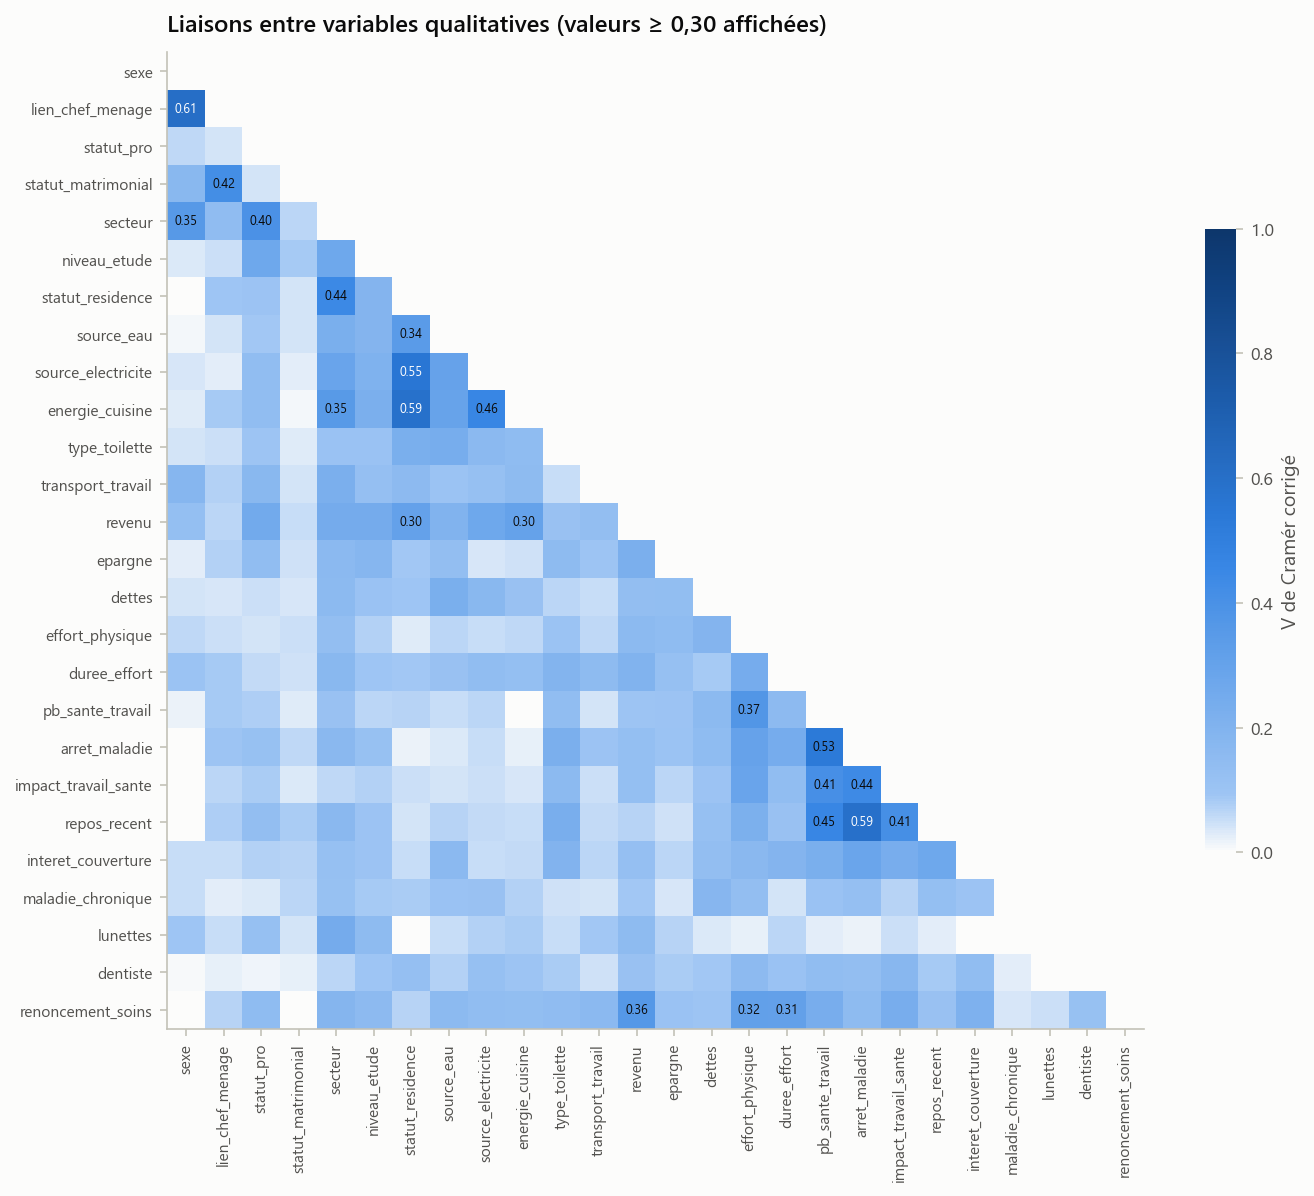

In [9]:
# V de Cramér (rampe séquentielle bleue)
from matplotlib.colors import LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list("bleu", ["#fcfcfb"] + o.RAMPE_BLEUE[2:])
fig, ax = plt.subplots(figsize=(10.5, 9))
masque = np.triu(np.ones(vmat.shape, dtype=bool))
im = ax.imshow(vmat.mask(masque), cmap=cmap, vmin=0, vmax=1)
ax.set_xticks(range(len(vmat)), vmat.columns, rotation=90, fontsize=7.5)
ax.set_yticks(range(len(vmat)), vmat.index, fontsize=7.5)
ax.grid(False)
for i in range(len(vmat)):
    for j in range(i):
        val = vmat.iloc[i, j]
        if val >= 0.3:
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=6,
                    color="white" if val > 0.55 else C["encre"])
cb = fig.colorbar(im, ax=ax, shrink=0.6)
cb.outline.set_visible(False)
cb.set_label("V de Cramér corrigé")
ax.set_title("Liaisons entre variables qualitatives (valeurs ≥ 0,30 affichées)")
o.sauver_figure(fig, RES, "v_de_cramer");

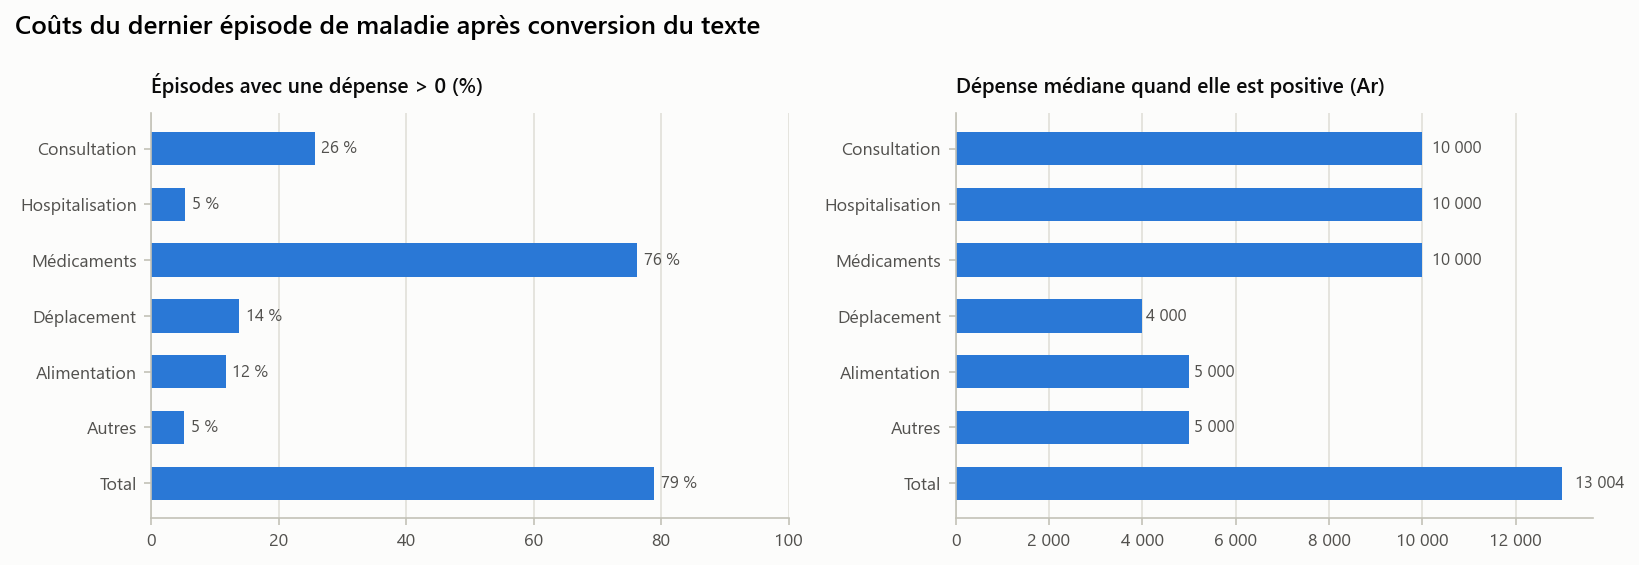


## Fichiers produits

- partie1_donnees\1.1_qualite\resultats\donnees_qualite.csv
- partie1_donnees\1.1_qualite\resultats\donnees_qualite.xlsx
- partie1_donnees\1.1_qualite\resultats\figures\couts_par_poste.png
- partie1_donnees\1.1_qualite\resultats\figures\v_de_cramer.png
- partie1_donnees\1.1_qualite\resultats\journal.txt
- partie1_donnees\1.1_qualite\resultats\tables\contradictions.csv
- partie1_donnees\1.1_qualite\resultats\tables\controles_plages.csv
- partie1_donnees\1.1_qualite\resultats\tables\conversion_texte_nombre.csv
- partie1_donnees\1.1_qualite\resultats\tables\couts_par_poste.csv
- partie1_donnees\1.1_qualite\resultats\tables\decisions_variables.csv
- partie1_donnees\1.1_qualite\resultats\tables\dominance_modalites.csv
- partie1_donnees\1.1_qualite\resultats\tables\paires_spearman.csv
- partie1_donnees\1.1_qualite\resultats\tables\paires_v_de_cramer.csv
- partie1_donnees\1.1_qualite\resultats\tables\recodage_modalites.csv
- partie1_donnees\1.1_qualite\resultats\tables\

In [10]:
# Coûts : part des épisodes avec dépense et médiane si dépense
noms = {"cout_consultation": "Consultation", "cout_hospitalisation": "Hospitalisation",
        "cout_medicaments": "Médicaments", "cout_deplacement": "Déplacement",
        "cout_alimentation": "Alimentation", "cout_autres": "Autres", "cout_total": "Total"}
rc = recap_couts.rename(index=noms)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].barh(rc.index[::-1], rc.pct_positifs[::-1], color=o.SERIES[0], height=0.6)
for y, v in enumerate(rc.pct_positifs[::-1]):
    axes[0].text(v + 1, y, f"{v:.0f} %", va="center", fontsize=8, color=C["encre2"])
axes[0].set_xlim(0, 100)
axes[0].set_title("Épisodes avec une dépense > 0 (%)", fontsize=10)
axes[1].barh(rc.index[::-1], rc.mediane_si_positif[::-1], color=o.SERIES[0], height=0.6)
for y, v in enumerate(rc.mediane_si_positif[::-1]):
    axes[1].text(v * 1.02, y, o.format_milliers(v), va="center", fontsize=8, color=C["encre2"])
axes[1].set_title("Dépense médiane quand elle est positive (Ar)", fontsize=10)
axes[1].xaxis.set_major_formatter(o.format_milliers)
for ax in axes:
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
fig.suptitle("Coûts du dernier épisode de maladie après conversion du texte", x=0.01, ha="left")
fig.tight_layout()
o.sauver_figure(fig, RES, "couts_par_poste")

log.section("Fichiers produits")
for f in sorted(RES.rglob("*.*")):
    log("-", f.relative_to(o.RACINE))
log.fermer();

---

Les tableaux complets sont dans `resultats/tables/`, les figures dans `resultats/figures/` et la sortie intégrale dans `resultats/journal.txt`. Commentaires et décisions : [README.md](README.md).